In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'invertebrate', 'marenaria')
pth_res = os.path.join(pth_data, 'results')
pth_clf = os.path.join(pth_res, 'classifier')
pth_out = os.path.join(pth_res, 'cancer', 'marenaria')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'invertebrate', 'marenaria')
pth_cb = os.path.join(pth_fig, 'colorbars')

In [3]:
fn = os.path.join(pth_clf, 'logreg.csv')
beta = pd.read_csv(fn, index_col = 0)
beta

,beta
GSE162534,0.562046
GSE229103,4.880419
rRNAModifications,3.368317
intercept_,1.128921


In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata

AnnData object with n_obs × n_vars = 8 × 43038
    obs: 'sample', 'GSE162534', 'GSE229103', 'rRNAModifications'
    uns: 'log1p', 'sample_colors'
    layers: 'counts', 'score'

In [5]:
# predict branches (logreg)
sig = lambda x: 100 / (1 + np.exp(-x))
X = adata.obs[beta.index[:-1]]
X['intercept_'] = 1.
prob = X.dot(beta).apply(sig)
adata.obs['Branch2'] = prob
adata.obs['Branch1'] = 100 - prob

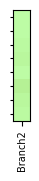

In [6]:
# probabilities heatmap
hm = sc.pl.heatmap(adata, 'Branch2', 'sample',
                   cmap = 'vanimo', vcenter = 50,
                   figsize = (1.5 * .365, 1.5),
                   show = False)

ax_hm = hm['heatmap_ax']
ax_grp = hm['groupby_ax']
ax_cb = ax_hm.figure.axes[1]
ax_grp.set_visible(False)
ax_cb.set_visible(False)

ax_hm.invert_yaxis()
for l in ax_hm.collections:
    l.remove()

ax_hm.tick_params('x', labelsize = 7)
ax_hm.set_yticks(np.arange(8))
ax_hm.tick_params('y', left = True, size = 2.5)

fn = os.path.join(pth_fig, 'probabilities.pdf')
plt.savefig(fn, bbox_inches = 'tight', dpi = 1200)

/tmp/ipykernel_2909148/1355066259.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 54.75x150 with 3 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax_cb.collections[1], cax = cax)


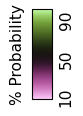

In [7]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax_cb.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('% Probability', size = 11, labelpad = 5)
cb.ax.yaxis.set_label_position('left')
cb.set_ticks([10, 50, 90])
cb.ax.tick_params('y', rotation = 90, labelsize = 11, pad = 5)
fn = os.path.join(pth_cb, 'probabilities.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [8]:
# save results
df = adata.obs[['Branch1', 'Branch2']].T
df.to_csv(os.path.join(pth_out, 'probabilities.csv'))

In [9]:
adata.write(os.path.join(pth_in, 'probabilities.h5ad'))